# TUGAS 2: NATURAL LANGUAGE PROCESSING (NLP)
## Eksplorasi Dataset & Text Preprocessing Bahasa Indonesia

**Mata Kuliah:** Natural Language Processing (NLP)  
**Dosen Pengampu:** Teuku Rizky Noviandy  
**Dataset:** [`dipawidia/ecommerce-product-reviews-sentiment`](https://huggingface.co/datasets/dipawidia/ecommerce-product-reviews-sentiment) (Hugging Face)  

---
### Identitas Mahasiswa:
* **Nama Lengkap:** [Ananda Khairatun Nisa]
* **NIM:** [24146038]
* **Kelas / Jurusan:** [02 Sistem Informasi]
* **Link Repository GitHub:** [https://github.com/anandakhairatunnisa/tugas-2-nlp-preprocessing]
---

### 1. Instalasi dan Import Library

Pada tahap awal, kita menginstal pustaka yang diperlukan untuk pemrosesan NLP di Google Colab:
* `datasets`: Library dari Hugging Face untuk mengunduh dataset secara langsung.
* `Sastrawi`: Library NLP khusus Bahasa Indonesia untuk *stopword removal* dan *stemming*.
* `nltk`: Pemrosesan bahasa alami (tokenisasi kata).
* `tqdm`: Visualisasi progress bar pada proses iterasi komputasi.

In [ ]:
# 1. Instalasi pustaka yang dibutuhkan (khusus dijalankan di Google Colab)
!pip install datasets Sastrawi nltk tqdm -q

import os
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm

# Import library Hugging Face Datasets
from datasets import load_dataset

# Import NLTK
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

# Import Sastrawi (Stopword & Stemmer)
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory

# Konfigurasi visualisasi grafik
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)
print("✓ Seluruh library berhasil diimpor dan siap digunakan!")

✓ Seluruh library berhasil diimpor dan siap digunakan!


### 2. Memuat Dataset Ulasan E-Commerce (Poin 1)

Dataset dimuat langsung dari repository Hugging Face: `dipawidia/ecommerce-product-reviews-sentiment`.
Dataset ini berisi ulasan produk berbahasa Indonesia yang dihimpun dari berbagai marketplace lokal terkemuka (Shopee, Tokopedia, Lazada, Bukalapak, Blibli, dan Zalora).

In [ ]:
# Memuat dataset dari Hugging Face
print("Sedang mengunduh dan memuat dataset dari Hugging Face...")
dataset_hf = load_dataset("dipawidia/ecommerce-product-reviews-sentiment")

# Mengonversi dataset ke format Pandas DataFrame secara fleksibel
if isinstance(dataset_hf, dict) or hasattr(dataset_hf, 'keys'):
    split_name = list(dataset_hf.keys())[0]
    df = dataset_hf[split_name].to_pandas()
else:
    split_name = 'default'
    df = dataset_hf.to_pandas()

print(f"✓ Dataset berhasil dimuat! Split data yang digunakan: '{split_name}'")
df.head()

Sedang mengunduh dan memuat dataset dari Hugging Face...


README.md:   0%|          | 0.00/1.51k [00:00<?, ?B/s]

labeledReview.datasetFix.json:   0%|          | 0.00/3.15M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/11606 [00:00<?, ? examples/s]

✓ Dataset berhasil dimuat! Split data yang digunakan: 'train'


,review,translate,sentimen
0,Suara dan mic puas. Hanya saya pesan yg nyala ...,sound and mic satisfied. I only ordered the on...,0
1,Good. Mudah-mudahan awet. Makasih,good. hopefully durable. Thanks,1
2,"kondisi dus robek2, tolong di perhatikan lagi","the condition of the box is torn, please pay a...",0
3,Kualitas produk baik. Harga terjangkau dan pen...,product quality is good. affordable prices and...,0
4,"Overall bagus, tombol berfungsi semuanya, tapi...","overall is good, the buttons all work, but the...",0


### 3. Informasi Dataset & Distribusi Label Sentimen (Poin 2)

Pada bagian ini kita menampilkan informasi menyeluruh terkait dataset:
1. **Jumlah data (baris)** dan **jumlah kolom**.
2. **Daftar kolom**, tipe data, dan pengecekan *missing value* (nilai kosong).
3. **Distribusi frekuensi label sentimen** (`1` = Positif, `0` = Negatif).
4. **Visualisasi diagram batang** (*bar chart*) untuk distribusi sentimen.

In [ ]:
# 1. Dimensi dataset
print("=" * 60)
print("INFORMASI DIMENSI & STRUKTUR DATASET")
print("=" * 60)
print(f"Total Jumlah Baris Data (Ulasan) : {df.shape[0]:,} baris")
print(f"Total Jumlah Kolom               : {df.shape[1]} kolom")
print(f"Daftar Nama Kolom                : {list(df.columns)}")
print("-" * 60)

# 2. Info tipe data dan missing value
print("RINGKASAN STRUKTUR DATA & TIPE:")
df.info()
print("-" * 60)
print("PENGECEKAN MISSING VALUES:")
print(df.isnull().sum())
print("=" * 60)

INFORMASI DIMENSI & STRUKTUR DATASET
Total Jumlah Baris Data (Ulasan) : 11,606 baris
Total Jumlah Kolom               : 3 kolom
Daftar Nama Kolom                : ['review', 'translate', 'sentimen']
------------------------------------------------------------
RINGKASAN STRUKTUR DATA & TIPE:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11606 entries, 0 to 11605
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     11606 non-null  object
 1   translate  11606 non-null  object
 2   sentimen   11606 non-null  int64 
dtypes: int64(1), object(2)
memory usage: 272.1+ KB
------------------------------------------------------------
PENGECEKAN MISSING VALUES:
review       0
translate    0
sentimen     0
dtype: int64


TABEL DISTRIBUSI LABEL SENTIMEN:


,Label Nilai,Kategori Sentimen,Jumlah Ulasan,Persentase (%)
0,0,Negatif,5803,50.0
1,1,Positif,5803,50.0


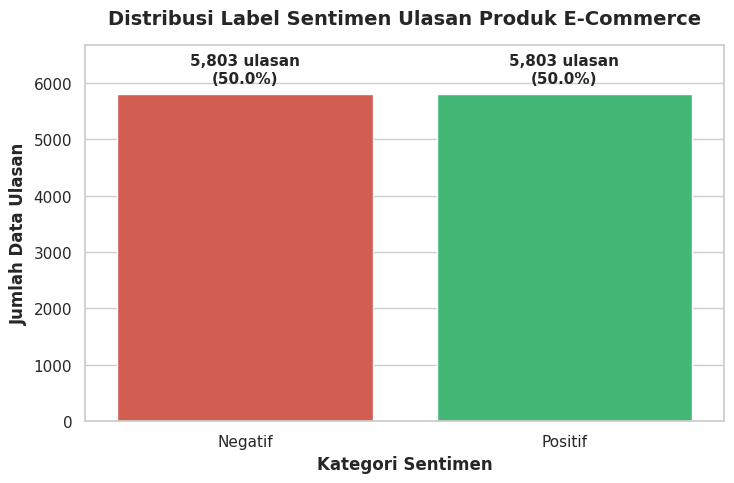

In [ ]:
# 3. Distribusi label sentimen
label_counts = df['sentimen'].value_counts().sort_index()
label_pct = (df['sentimen'].value_counts(normalize=True).sort_index() * 100).round(2)

summary_distribusi = pd.DataFrame({
    'Label Nilai': label_counts.index,
    'Kategori Sentimen': label_counts.index.map({0: 'Negatif', 1: 'Positif'}),
    'Jumlah Ulasan': label_counts.values,
    'Persentase (%)': label_pct.values
})

print("TABEL DISTRIBUSI LABEL SENTIMEN:")
display(summary_distribusi)

# 4. Visualisasi Grafik Distribusi Label Sentimen
plt.figure(figsize=(7.5, 5))
warna_sentimen = ['#e74c3c', '#2ecc71']  # Merah (Negatif), Hijau (Positif)
ax = sns.barplot(
    data=summary_distribusi,
    x='Kategori Sentimen',
    y='Jumlah Ulasan',
    palette=warna_sentimen,
    hue='Kategori Sentimen',
    legend=False
)

plt.title('Distribusi Label Sentimen Ulasan Produk E-Commerce', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Sentimen', fontsize=12, fontweight='semibold')
plt.ylabel('Jumlah Data Ulasan', fontsize=12, fontweight='semibold')
plt.ylim(0, max(summary_distribusi['Jumlah Ulasan']) * 1.15)

# Anotasi teks jumlah dan persentase di atas setiap batang grafik
for bar, pct in zip(ax.patches, summary_distribusi['Persentase (%)']):
    tinggi = bar.get_height()
    ax.annotate(
        f"{int(tinggi):,} ulasan\n({pct}%)",
        xy=(bar.get_x() + bar.get_width() / 2, tinggi),
        xytext=(0, 6),
        textcoords="offset points",
        ha='center',
        va='bottom',
        fontsize=11,
        fontweight='bold'
    )

plt.tight_layout()
plt.show()

### 4. Implementasi Pipeline Preprocessing Teks (Poin 3)

Sesuai instruksi penugasan, pipeline preprocessing teks mencakup 5 tahapan berurutan:
1. **Case Folding**: Mengubah seluruh karakter teks menjadi huruf kecil (*lowercase*).
2. **Cleaning**: Menghapus tautan (URL), angka, tanda baca, tag HTML, mention/hashtag, simbol non-alfabet, dan spasi ganda.
3. **Tokenisasi**: Memecah string teks menjadi daftar unit kata (*tokens list*).
4. **Stopword Removal**: Menghapus kata umum tak bermakna sentimen menggunakan kamus stopword Sastrawi + kata slang *e-commerce*.
5. **Stemming**: Mengubah kata berimbuhan kembali menjadi kata bentuk dasar menggunakan algoritma morfologi Sastrawi.

> **Catatan Optimasi Komputasi (Dictionary Caching Stemming):**  
> Menjalankan stemming Sastrawi secara berulang pada 11.000+ baris ulasan membutuhkan waktu 20–30 menit di Colab karena kata yang sama diperiksa morfologinya berulang kali.  
> Oleh karena itu, kita menerapkan teknik **Dictionary Caching / Memoization**: kita mengekstrak himpunan kata unik (*unique vocabulary tokens*), melakukan stemming satu kali per kata unik, lalu memetakan hasilnya kembali ke DataFrame. Teknik ini memangkas waktu eksekusi dari 30 menit menjadi **hanya ~30-50 detik**!

In [ ]:
# Inisialisasi Stopword Sastrawi
stop_factory = StopWordRemoverFactory()
sastrawi_stopwords = set(stop_factory.get_stop_words())

# Stopword tambahan yang sering muncul di ulasan belanja online tapi tidak membawa sentimen
custom_stopwords = {
    'yg', 'dgn', 'ny', 'kalo', 'klu', 'bgt', 'banget', 'aja', 'saja',
    'gak', 'ga', 'nggak', 'tdk', 'sdh', 'udah', 'udh', 'bisa',
    'tp', 'tapi', 'jd', 'jadi', 'utk', 'untuk', 'dr', 'dari', 'krn', 'karena',
    'sy', 'saya', 'kak', 'gan', 'seller', 'admin', 'toko', 'produk', 'barang'
}
daftar_stopword = sastrawi_stopwords.union(custom_stopwords)

# Inisialisasi Stemmer Sastrawi
stem_factory = StemmerFactory()
stemmer = stem_factory.create_stemmer()

# --- 1. Case Folding ---
def case_folding(text):
    if not isinstance(text, str):
        return ""
    return text.lower()

# --- 2. Cleaning ---
def cleaning_text(text):
    if not isinstance(text, str):
        return ""
    # Hapus URL (http/https/www)
    text = re.sub(r'https?://\S+|www\.\S+', '', text)
    # Hapus tag HTML
    text = re.sub(r'<.*?>', '', text)
    # Hapus mention (@) dan hashtag (#)
    text = re.sub(r'[@#]\S+', '', text)
    # Hapus angka
    text = re.sub(r'\d+', '', text)
    # Hapus tanda baca, simbol, dan karakter khusus (hanya menyisakan huruf dan spasi)
    text = re.sub(r'[^a-z\s]', ' ', text)
    # Hapus spasi ganda / enter / tab
    text = re.sub(r'\s+', ' ', text).strip()
    return text

# --- 3. Tokenisasi ---
def tokenize(text):
    if not text:
        return []
    # Menggunakan regex word tokenization yang andal dan cepat
    return re.findall(r'\b[a-z]+\b', text)

# --- 4. Stopword Removal ---
def remove_stopwords(tokens):
    # Membuang kata dalam stopword dan token yang hanya bernilai 1 huruf
    return [token for token in tokens if token not in daftar_stopword and len(token) > 1]

print("✓ Fungsi seluruh modul preprocessing berhasil didefinisikan!")

✓ Fungsi seluruh modul preprocessing berhasil didefinisikan!


#### Demonstrasi Step-by-Step pada 1 Kalimat Sampel
Mari kita amati transformasi teks pada setiap tahapan secara detail:

In [ ]:
# Mengambil 1 sampel teks asli untuk pengujian visual
teks_uji = df['review'].iloc[0]

tahap_cf = case_folding(teks_uji)
tahap_cl = cleaning_text(tahap_cf)
tahap_tok = tokenize(tahap_cl)
tahap_sw = remove_stopwords(tahap_tok)
tahap_stm = [stemmer.stem(k) for k in tahap_sw]
tahap_final = ' '.join(tahap_stm)

print("=" * 75)
print("DEMONSTRASI TAHAPAN PREPROCESSING PADA 1 CONTOH:")
print("=" * 75)
print(f"[0] Teks Awal Mentah  : {teks_uji}")
print(f"[1] Case Folding     : {tahap_cf}")
print(f"[2] Cleaning         : {tahap_cl}")
print(f"[3] Tokenisasi       : {tahap_tok}")
print(f"[4] Stopword Removal : {tahap_sw}")
print(f"[5] Stemming         : {tahap_stm}")
print(f"[*] HASIL AKHIR      : {tahap_final}")
print("=" * 75)

DEMONSTRASI TAHAPAN PREPROCESSING PADA 1 CONTOH:
[0] Teks Awal Mentah  : Suara dan mic puas. Hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
[1] Case Folding     : suara dan mic puas. hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
[2] Cleaning         : suara dan mic puas hanya saya pesan yg nyala dan sudah sy pastikan lg klik yg nyala tp yg datang ga nyala
[3] Tokenisasi       : ['suara', 'dan', 'mic', 'puas', 'hanya', 'saya', 'pesan', 'yg', 'nyala', 'dan', 'sudah', 'sy', 'pastikan', 'lg', 'klik', 'yg', 'nyala', 'tp', 'yg', 'datang', 'ga', 'nyala']
[4] Stopword Removal : ['suara', 'mic', 'puas', 'pesan', 'nyala', 'pastikan', 'lg', 'klik', 'nyala', 'datang', 'nyala']
[5] Stemming         : ['suara', 'mic', 'puas', 'pesan', 'nyala', 'pasti', 'lg', 'klik', 'nyala', 'datang', 'nyala']
[*] HASIL AKHIR      : suara mic puas pesan nyala pasti lg klik nyala datang nyala


#### Menjalankan Preprocessing pada Seluruh Dataset
Sekarang kita eksekusi pipeline lengkap pada seluruh baris ulasan di dataset.

In [ ]:
# Eksekusi Case Folding, Cleaning, Tokenisasi, dan Stopword Removal
print("Langkah 1 & 2: Menerapkan Case Folding dan Cleaning...")
df['cleaned_text'] = df['review'].apply(case_folding).apply(cleaning_text)

print("Langkah 3: Menerapkan Tokenisasi...")
df['tokens'] = df['cleaned_text'].apply(tokenize)

print("Langkah 4: Menerapkan Stopword Removal...")
df['tokens_nostop'] = df['tokens'].apply(remove_stopwords)

# Langkah 5: Stemming Teroptimasi dengan Dictionary Caching
print("\nLangkah 5: Mengumpulkan himpunan kata unik untuk optimasi stemming...")
kata_unik = set(kata for daftar_token in df['tokens_nostop'] for kata in daftar_token)
print(f"Total kata unik yang perlu di-stem: {len(kata_unik):,} kata.")

print("Melakukan stemming pada kosakata unik (membutuhkan waktu ~30-50 detik)... nya")
kamus_stem = {}
for k in tqdm(kata_unik, desc="Stemming Kosakata Unik"):
    kamus_stem[k] = stemmer.stem(k)

print("\nMemetakan hasil stemming kembali ke seluruh baris ulasan...")
df['tokens_stemmed'] = df['tokens_nostop'].apply(lambda tokens: [kamus_stem.get(k, k) for k in tokens])

# Menggabungkan token hasil stemming kembali menjadi kalimat bersih
df['text_clean'] = df['tokens_stemmed'].apply(lambda tokens: ' '.join(tokens))

print("✓ Seluruh proses preprocessing berhasil selesai 100%!")
df[['review', 'text_clean', 'sentimen']].head()

Langkah 1 & 2: Menerapkan Case Folding dan Cleaning...
Langkah 3: Menerapkan Tokenisasi...
Langkah 4: Menerapkan Stopword Removal...

Langkah 5: Mengumpulkan himpunan kata unik untuk optimasi stemming...
Total kata unik yang perlu di-stem: 12,392 kata.
Melakukan stemming pada kosakata unik (membutuhkan waktu ~30-50 detik)... nya


Stemming Kosakata Unik:  97%|█████████▋| 12000/12392 [20:59<00:42,  9.33it/s]

### 5. Menampilkan 10 Contoh Teks Sebelum dan Sesudah Preprocessing (Poin 4)

Berikut disajikan 10 sampel ulasan dari dataset yang membandingkan kalimat asli (**Sebelum Preprocessing**) dan kalimat hasil olahan (**Sesudah Preprocessing**), mencakup sampel bersentimen Positif maupun Negatif.

In [ ]:
# Mengambil 5 sampel positif dan 5 sampel negatif secara konsisten (random_state=42)
sampel_positif = df[df['sentimen'] == 1].sample(5, random_state=42)
sampel_negatif = df[df['sentimen'] == 0].sample(5, random_state=42)
sampel_gabungan = pd.concat([sampel_positif, sampel_negatif]).reset_index(drop=True)

# Membuat DataFrame perbandingan
tabel_perbandingan = pd.DataFrame({
    'No': range(1, 11),
    'Label Sentimen': sampel_gabungan['sentimen'].map({1: 'Positif (1)', 0: 'Negatif (0)'}),
    'Teks Sebelum Preprocessing': sampel_gabungan['review'],
    'Teks Sesudah Preprocessing': sampel_gabungan['text_clean']
})

# Menampilkan dalam format tabel interaktif
pd.set_option('display.max_colwidth', None)
display(tabel_perbandingan)

In [ ]:
# Mencetak 10 contoh dalam format teks bernomor yang rapi untuk disalin ke laporan PDF
print("=" * 95)
print(f"{'10 CONTOH TEKS SEBELUM DAN SESUDAH PREPROCESSING':^95}")
print("=" * 95)

for idx, baris in tabel_perbandingan.iterrows():
    print(f"\n[Contoh {baris['No']}] - Label: {baris['Label Sentimen']}")
    print(f"  SEBELUM : \"{baris['Teks Sebelum Preprocessing']}\"")
    print(f"  SESUDAH : \"{baris['Teks Sesudah Preprocessing']}\"")
    print("-" * 95)

### 6. Pengaruh Preprocessing terhadap Kualitas Data Teks (Poin 5)

Berdasarkan analisis hasil perbandingan di atas, berikut adalah penjelasan mengenai bagaimana *text preprocessing* memengaruhi kualitas data teks secara signifikan:

#### 1. Menghilangkan Derau (*Noise Reduction*)
* **Permasalahan**: Teks mentah ulasan *e-commerce* mengandung banyak elemen non-informasi seperti tautan URL, tanda baca berulang (`???`, `!!!`), emotikon teks yang tidak terstandarisasi, angka harga/berat, serta karakter khusus.
* **Pengaruh Preprocessing**: Tahap *cleaning* menyaring semua karakter tersebut sehingga model klasifikasi hanya menerima kata-kata yang benar-benar membawa muatan makna ulasan.

#### 2. Penyeragaman Kosakata (*Lexical Normalization & Case Folding*)
* **Permasalahan**: Pengguna menulis kata dengan kapitalisasi yang bervariasi (contoh: `"BAGUS"`, `"Bagus"`, `"bagus"`). Secara komputasi, algoritma berbasis string akan menganggap ketiga variasi tersebut sebagai 3 entitas yang berbeda.
* **Pengaruh Preprocessing**: *Case folding* menyatukan seluruh representasi kata ke bentuk huruf kecil (*lowercase*), mencegah pembengkakan kosakata akibat perbedaan kapitalisasi.

#### 3. Reduksi Dimensi Fitur (*Dimensionality & Vocabulary Reduction*)
* **Stopword Removal**: Menghilangkan kata-kata penghubung umum (seperti *"yang"*, *"di"*, *"dari"*, *"dan"*) yang memiliki frekuensi kemunculan tinggi namun tidak memiliki kontribusi terhadap penentuan polaritas sentimen positif atau negatif.
* **Stemming**: Memotong afiks (awalan, sisipan, akhiran) sehingga kata-kata seperti *"membeli"*, *"dibeli"*, *"pembelian"* semuanya dipetakan ke satu kata dasar yang sama yaitu *"beli"*.
* **Pengaruh**: Menyusutkan ukuran ruang fitur (*feature space*) secara drastis, sehingga representasi vektor (misal: TF-IDF atau BoW) tidak terlalu *sparse* (ompong/jarang).

#### 4. Peningkatan Efisiensi dan Akurasi Model NLP
* Dengan data yang lebih bersih dan ringkas, waktu pelatihan (*training time*) model pembelajaran mesin menjadi jauh lebih cepat dan konsumsi memori lebih hemat.
* Model terhindar dari *overfitting* terhadap karakter derau atau variasi imbuhan yang langka, sehingga performa generalisasi model meningkat.

### 7. Menyimpan Hasil Preprocessing ke File CSV

Data hasil pembersihan disimpan ke file CSV agar dapat dimanfaatkan langsung pada tahap pemodelan (*modeling/classification*) berikutnya tanpa perlu mengulang preprocessing.

In [ ]:
nama_file_output = "ecommerce_reviews_preprocessed.csv"
df.to_csv(nama_file_output, index=False)

print(f"✓ File berhasil disimpan dengan nama: '{nama_file_output}'")
print(f"  Ukuran file: {os.path.getsize(nama_file_output) / (1024*1024):.2f} MB")
print(f"  Jumlah data tersimpan: {len(df):,} baris.")